# HW2 – 1. Data understanding and preprocessing (VisDrone)

## 1. Setup

In [1]:
# Make the repo importable: Kaggle clones it, locally the root is the parent of notebooks/
import os, sys
from pathlib import Path
if os.path.exists("/kaggle/working"):
    if not os.path.exists("/kaggle/working/repo"):
        !git clone --depth 1 https://github.com/BohdanZasymovych/ai-hw2-object-detection.git /kaggle/working/repo
    !pip install -q pycocotools huggingface_hub   # only if missing; torch/torchvision stay Kaggle's own CUDA builds
    ROOT_DIR = Path("/kaggle/working/repo")
else:
    ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR))

In [2]:
# Live reload of utils/common.py when editing locally (Kaggle's IPython autoreload is broken on Python 3.13)
if not os.path.exists("/kaggle/working"):
    %load_ext autoreload
    %autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.common import *

seed_everything()
download_data()          # local: kaggle download + unzip into data/raw (skipped if present); Kaggle: data is attached
print(env_info(), "| data:", RAW_DIR)

Using dataset in /home/bohdan/code/ai/hw2-object-detection/data/raw
{'python': '3.14.4', 'torch': '2.15.0+cu132', 'torchvision': '0.29.2+cu132', 'gpu': 'NVIDIA GeForce RTX 2050', 'on_kaggle': False} | data: /home/bohdan/code/ai/hw2-object-detection/data/raw


In [3]:
# Quick look at the dataset layout
for p in sorted(RAW_DIR.iterdir()):
    n = sum(1 for _ in p.rglob("*")) if p.is_dir() else 1
    print(f"{p.name:40s} {'dir ' if p.is_dir() else 'file'} {n} entries")

test                                     dir  3860 entries
test_images.csv                          file 1 entries
train                                    dir  66659 entries
val                                      dir  7150 entries


## 2. Data understanding & preprocessing

Goal: understand the data before modelling and fix the preprocessing protocol. The dataset is VisDrone video (drone footage), already merged to 8 classes, shipped as COCO JSON (`annotations_coco.json`) and YOLO txt labels (`labels/`, `ignore/`).

### 2.1 Dataset overview

In [4]:
# Clean per-split tables from the shared loader (frames, real boxes, ignore regions)
imgs, boxes, ignore = {}, {}, {}
for s in ["train", "val"]:
    imgs[s], boxes[s], ignore[s] = load_split(s)
test = pd.read_csv(RAW_DIR / "test_images.csv")

rows = []
for s in ["train", "val"]:
    rows.append({"split": s, "sequences": imgs[s].seq.nunique(), "frames": len(imgs[s]),
                 "boxes": len(boxes[s]),
                 "resolutions": ", ".join(f"{w}x{h}" for w, h in imgs[s][["width", "height"]].drop_duplicates().values)})
rows.append({"split": "test", "sequences": test["clip"].nunique(), "frames": len(test), "boxes": "hidden",
             "resolutions": ", ".join(f"{w}x{h}" for w, h in test[["width", "height"]].drop_duplicates().values)})
pd.DataFrame(rows).set_index("split")

,sequences,frames,boxes,resolutions
split,,,,
train,56,24201,1105516,"1344x756, 1904x1071, 2688x1512, 1920x1080, 136..."
val,7,2846,114132,"1344x756, 2720x1530, 2688x1512, 3840x2160, 190..."
test,48,3811,hidden,"1920x1080, 1344x756, 1360x764, 1904x1072, 680x..."


In [5]:
# Split sanity: train and val must not share any sequence (frames of one video are highly correlated)
overlap = set(imgs["train"].seq) & set(imgs["val"].seq)
print("Shared train/val sequences:", overlap or "none")

Shared train/val sequences: none


**Findings.** The provided train/val split is already by sequence (no shared videos): 56 train / 7 val sequences, 24k / 2.8k frames, 1.1M / 114k boxes. Resolutions vary from 680 px to 4K wide, and the test set (48 separate clips, 3.8k frames) is mixed-resolution as well, so a fixed resize is needed. The val set is small (7 videos), so its metrics are noisy.

### 2.2 Annotation format and ignored regions

In [6]:
# Cross-check the COCO json against the YOLO txt labels: number of boxes must match
for s in ["train", "val"]:
    n_txt = sum(sum(1 for _ in open(f)) for f in (RAW_DIR / s / "labels").rglob("*.txt"))
    n_ign = sum(sum(1 for _ in open(f)) for f in (RAW_DIR / s / "ignore").rglob("*.txt"))
    n_json = len(boxes[s])
    n_ign_json = len(ignore[s])
    print(f"{s}: boxes json={n_json} txt={n_txt} | ignore regions json={n_ign_json} txt={n_ign}")

train: boxes json=1105516 txt=1105516 | ignore regions json=63843 txt=63843


val: boxes json=114132 txt=114132 | ignore regions json=3995 txt=3995


**Handling.** VisDrone `ignored regions` (id 0) and `others` (id 11) are stored with `iscrowd=1`, copied once per class. The JSON and YOLO labels match box-for-box. Rules:
- **Training:** only `iscrowd=0` boxes (8 classes; pedestrian+people → `person`, tricycle+awning-tricycle → `tricycle`). Ignore regions are not targets.
- **Evaluation:** keep `iscrowd=1` entries so `pycocotools` skips detections inside them.

In [7]:
# Quality checks on the training boxes
b = boxes["train"]
print("degenerate boxes (w<2 or h<2 px):", int(((b.w < 2) | (b.h < 2)).sum()),
      "| occlusion levels (%):", (b.occlusion.value_counts(normalize=True) * 100).round(0).to_dict(),
      "| truncated (%):", round((b.truncation > 0).mean() * 100))

degenerate boxes (w<2 or h<2 px): 0 | occlusion levels (%): {0.0: 54.0, 1.0: 40.0, 2.0: 5.0} | truncated (%): 4


### 2.3 Sample frames (conversion check)

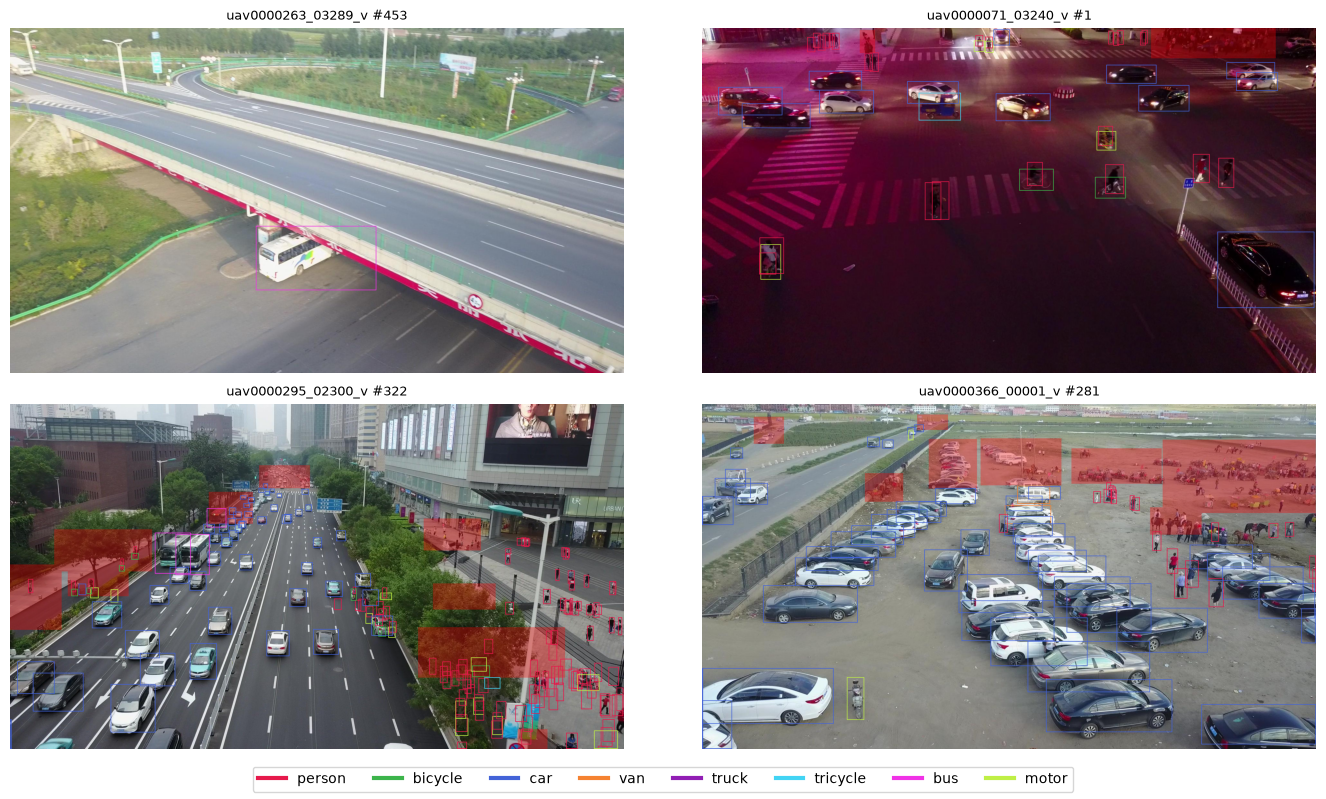

In [8]:
# GT boxes (coloured by class) and ignore regions (red) with the shared draw_frame
# sparsest, median and densest frame + a random frame with ignore regions
per_frame = boxes["train"].groupby("image_id").size()
ign_ids = set(ignore["train"].image_id)
picks = [per_frame.idxmin(), per_frame.sub(per_frame.median()).abs().idxmin(), per_frame.idxmax()]
picks.append(next(i for i in per_frame.sample(frac=1, random_state=SEED).index if i in ign_ids and i not in picks))
fig, axs = plt.subplots(2, 2, figsize=(14, 8))
for ax, i in zip(axs.ravel(), picks):
    draw_frame("train", i, ax)
fig.legend(handles=[plt.Line2D([], [], color=c, lw=3, label=n) for c, n in zip(COLORS, CLASSES)], loc="lower center", ncol=8)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

**Findings.** Boxes line up with objects and ignore regions (red) cover crowds/unlabelled areas, so the conversion is correct. Objects are tiny relative to the frame and often densely packed.

### 2.4 Class distribution

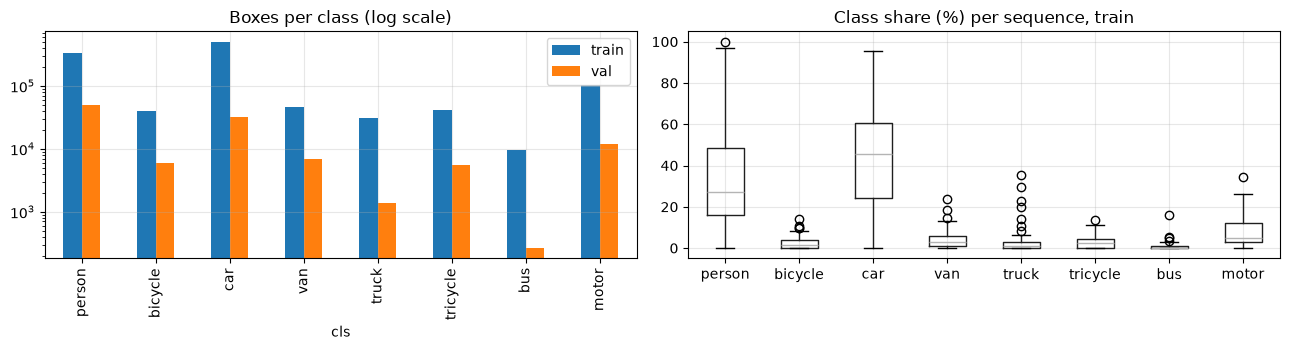

           train    val  train %  val %
cls                                    
person    328701  50312     29.7   44.1
bicycle    40255   6022      3.6    5.3
car       505301  31821     45.7   27.9
van        46940   6842      4.2    6.0
truck      30498   1359      2.8    1.2
tricycle   41349   5487      3.7    4.8
bus         9653    264      0.9    0.2
motor     102819  12025      9.3   10.5
Sequences without class: {'person': 1, 'bicycle': 15, 'car': 7, 'van': 10, 'truck': 17, 'tricycle': 17, 'bus': 32, 'motor': 6}


In [9]:
cnt = pd.DataFrame({s: boxes[s].cls.value_counts() for s in boxes}).reindex(CLASSES)
share = (cnt / cnt.sum() * 100).round(1)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
cnt.plot.bar(ax=axs[0], logy=True, title="Boxes per class (log scale)")
# Per-sequence class mix: does the dominant class differ between videos?
mix = boxes["train"].groupby(["seq", "cls"]).size().unstack(fill_value=0).reindex(columns=CLASSES)
(mix.div(mix.sum(axis=1), axis=0) * 100).boxplot(ax=axs[1]); axs[1].set_title("Class share (%) per sequence, train")
plt.tight_layout(); plt.show()
print(pd.concat([cnt, share.add_suffix(" %")], axis=1))
print("Sequences without class:", (mix == 0).sum().to_dict())

**Findings.** Strong imbalance: car (46%) and person (30%) dominate, `bus` is under 1% and `truck`/`tricycle`/`bicycle` are 3-4% each. Class mix is sequence-specific (e.g. no bus in 32 of 56 sequences), and val has a different mix from train (more person, fewer car, only 264 buses), so per-class AP on val, especially bus, will be noisy. Consider class-aware losses or sampling for rare classes.

### 2.5 Object size

COCO size buckets (% of boxes):
 size
medium    63.5
small     24.9
large     11.6

sqrt(area) percentiles [px]: {0.05: 20.0, 0.25: 32.0, 0.5: 46.0, 0.75: 68.0, 0.95: 130.0}
median box height / image height: 0.044


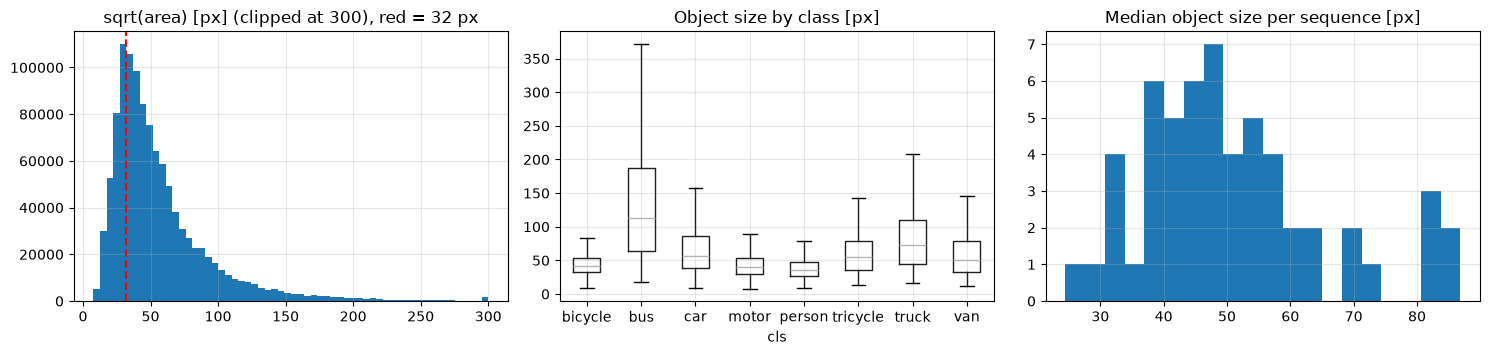

size      small  medium  large
cls                           
person     39.0    60.0    0.0
bicycle    24.0    74.0    1.0
car        16.0    64.0   19.0
van        21.0    63.0   16.0
truck       9.0    58.0   33.0
tricycle   21.0    66.0   13.0
bus         4.0    39.0   57.0
motor      30.0    68.0    1.0
per-sequence median size: min 24, max 87 px

After resize, long side L:
                  640   960   1280  1920
% boxes < 16 px  54.2  24.0   9.8   1.7


In [10]:
bt = boxes["train"]
SMALL, MEDIUM = 32, 96   # COCO thresholds on sqrt(area), native pixels
bt_size = pd.cut(bt["size"], [0, SMALL, MEDIUM, 1e9], labels=["small", "medium", "large"])
print("COCO size buckets (% of boxes):\n", (bt_size.value_counts(normalize=True) * 100).round(1).to_string())
print("\nsqrt(area) percentiles [px]:", bt["size"].quantile([.05, .25, .5, .75, .95]).round(0).to_dict())
print("median box height / image height: %.3f" % bt.rel_h.median())

seq_size = bt.groupby("seq")["size"].median()
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].hist(bt["size"].clip(upper=300), bins=60); axs[0].axvline(32, c="r", ls="--"); axs[0].set_title("sqrt(area) [px] (clipped at 300), red = 32 px")
bt.boxplot(column="size", by="cls", ax=axs[1], showfliers=False); axs[1].set_title("Object size by class [px]"); plt.suptitle("")
axs[2].hist(seq_size, bins=20); axs[2].set_title("Median object size per sequence [px]")
plt.tight_layout(); plt.show()
print(pd.crosstab(bt.cls, bt_size, normalize="index").mul(100).round(0).reindex(CLASSES))
print("per-sequence median size: min %.0f, max %.0f px" % (seq_size.min(), seq_size.max()))

# Effective size after resizing the long side to L: how many boxes become tiny (<16 px)?
eff = pd.DataFrame({L: (bt["size"] * L / bt.width < 16).mean() * 100 for L in [640, 960, 1280, 1920]}, index=["% boxes < 16 px"]).round(1)
print("\nAfter resize, long side L:\n", eff.to_string())

In [11]:
# Box-shape clusters (k-means on relative w,h, 1-IoU distance as in YOLOv2) -> anchor config
def iou_wh(wh, c):
    inter = np.minimum(wh[:, None, 0], c[None, :, 0]) * np.minimum(wh[:, None, 1], c[None, :, 1])
    return inter / (wh[:, 0:1] * wh[:, 1:2] + (c[:, 0] * c[:, 1])[None] - inter)


def kmeans_anchors(wh, k, iters=50, seed=SEED):
    rng = np.random.default_rng(seed)
    c = wh[rng.choice(len(wh), k, replace=False)]
    for _ in range(iters):
        a = iou_wh(wh, c).argmax(1)
        c = np.array([np.median(wh[a == j], axis=0) if (a == j).any() else c[j] for j in range(k)])
    return c[np.argsort(c[:, 0] * c[:, 1])], iou_wh(wh, c).max(1).mean()


wh = bt[["rel_w", "rel_h"]].sample(200_000, random_state=SEED).to_numpy()
INPUT_LONG = 1280   # candidate long-side input resolution (see 2.8)
for k in [3, 5, 9]:
    c, miou = kmeans_anchors(wh, k)
    px = (c * [INPUT_LONG, INPUT_LONG * 9 / 16]).round(0).astype(int)
    print(f"k={k}: mean best-IoU={miou:.2f}  anchors (w,h) at {INPUT_LONG}px:", [tuple(int(v) for v in p) for p in px])
print("aspect ratio h/w percentiles:", (bt.h / bt.w).quantile([.1, .5, .9]).round(2).to_dict())

k=3: mean best-IoU=0.60  anchors (w,h) at 1280px: [(15, 21), (32, 32), (75, 58)]


k=5: mean best-IoU=0.66  anchors (w,h) at 1280px: [(13, 18), (19, 34), (32, 23), (44, 41), (92, 66)]


k=9: mean best-IoU=0.73  anchors (w,h) at 1280px: [(11, 15), (13, 28), (22, 19), (20, 39), (40, 22), (30, 31), (39, 53), (63, 34), (100, 72)]
aspect ratio h/w percentiles: {0.1: 0.47, 0.5: 1.06, 0.9: 2.25}


**Findings.** Objects are small: median box height is 4.4% of the frame, and 25% of boxes are COCO-small (<32 px) at native resolution (bus/truck are the large ones, person/motor the smallest). The median size per sequence ranges 24-87 px, so scale varies between videos (flight altitude). Downscaling hurts quickly: at long side 640 px, 54% of boxes would be under 16 px; at 1280 px it is 10%, at 1920 px under 2%. **We use a 1280 px long side** (960 px as a cheaper fallback). Box shapes are mostly near-square to tall (h/w 0.47-2.25 for the 10th-90th percentile), so anchor aspect ratios {0.5, 1, 2} cover them. K-means anchors at 1280 px are about 13-100 px, so anchor sizes should start at 16 px (not the 32 px framework default), for example 16/32/64/128 with a high-resolution (stride 4 or 8) level.

### 2.6 Scene density

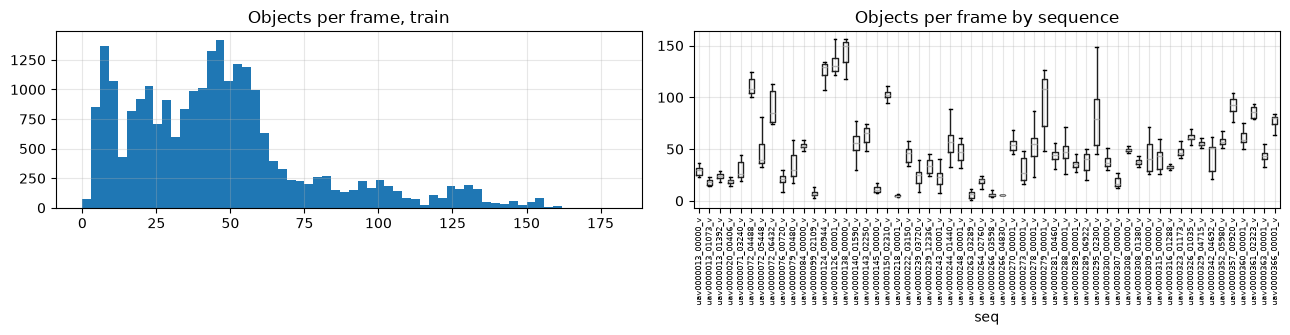

per frame: mean 45.7 | median 43 | p95 118 | max 180
val   per frame: mean 40.1 | max 116
sequence mean density: min 5.1, max 143.0
frames with empty / >100 / >200 objects (%): 0.0 / 7.6 / 0.0


In [12]:
dens = {s: boxes[s].groupby("image_id").size().reindex(imgs[s].image_id, fill_value=0) for s in boxes}
dens_seq = imgs["train"].assign(n=dens["train"].values).groupby("seq").n.agg(["mean", "max"]).round(1)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
axs[0].hist(dens["train"], bins=60); axs[0].set_title("Objects per frame, train")
imgs["train"].assign(n=dens["train"].values).boxplot(column="n", by="seq", ax=axs[1], showfliers=False)
axs[1].set_title("Objects per frame by sequence"); axs[1].tick_params(axis="x", labelrotation=90, labelsize=6); plt.suptitle("")
plt.tight_layout(); plt.show()
print("per frame: mean %.1f | median %.0f | p95 %.0f | max %d" % (dens["train"].mean(), dens["train"].median(), dens["train"].quantile(.95), dens["train"].max()))
print("val   per frame: mean %.1f | max %d" % (dens["val"].mean(), dens["val"].max()))
print("sequence mean density: min %.1f, max %.1f" % (dens_seq["mean"].min(), dens_seq["mean"].max()))
print("frames with empty / >100 / >200 objects (%%): %.1f / %.1f / %.1f" % tuple((dens["train"].agg([lambda x: (x == 0).mean(), lambda x: (x > 100).mean(), lambda x: (x > 200).mean()]) * 100)))

**Findings.** Dense scenes: 46 objects per frame on average, 7.6% of frames have more than 100 and the maximum is 180, so the max detections per image must be at least 300 (also the lower bound for DETR queries). Density varies much more between sequences (mean 5 to 143) than within them, so the 7 val videos cover only part of the range. Dense frames contain many small, partly occluded objects (46% of boxes are occluded or truncated), where NMS can suppress true neighbours (Soft-NMS is worth trying).

### 2.7 Temporal redundancy (frame subsampling)

In [13]:
# How much do boxes move between frame t and t+k? IoU of the same track (track_id) across a gap of k frames
def track_iou(df, k):
    a = df[["seq", "track_id", "frame_id", "x", "y", "w", "h"]]
    b = a.assign(frame_id=a.frame_id - k)
    m = a.merge(b, on=["seq", "track_id", "frame_id"], suffixes=("", "2"))
    ix = (np.minimum(m.x + m.w, m.x2 + m.w2) - np.maximum(m.x, m.x2)).clip(lower=0)
    iy = (np.minimum(m.y + m.h, m.y2 + m.h2) - np.maximum(m.y, m.y2)).clip(lower=0)
    inter = ix * iy
    return inter / (m.w * m.h + m.w2 * m.h2 - inter)


bf = bt.merge(imgs["train"][["image_id", "frame_id"]], on="image_id", suffixes=("", "_"))
res = {k: track_iou(bf, k) for k in [1, 2, 3, 5, 10]}
print(pd.DataFrame({"k (frame gap)": list(res), "median IoU of same object": [round(v.median(), 2) for v in res.values()],
                    "% with IoU>0.5": [round((v > .5).mean() * 100) for v in res.values()]}).to_string(index=False))

 k (frame gap)  median IoU of same object  % with IoU>0.5
             1                       0.90              96
             2                       0.81              86
             3                       0.73              75
             5                       0.60              59
            10                       0.36              39


**Findings.** The same object keeps IoU 0.90 between neighbouring frames and still 0.73 three frames apart, so consecutive frames are near-duplicates. **We keep every 3rd frame** (8,090 train / 951 val frames): this cuts training cost 3x, while overlapping objects with IoU>0.5 still make the retained frames meaningfully different (a larger step of 5-10 loses more diversity per frame than it saves). Using more frames with fewer epochs is equivalent in cost, so this can be revisited in the final pipeline.

### 2.8 Preprocessing and training protocol

In [14]:
# The protocol lives in section 1.2 (PREP); here: what it gives after frame subsampling
print(PREP)
kept = {s: subsample(imgs[s]) for s in imgs}
print({s: f"{len(imgs[s])} -> {len(kept[s])} frames" for s in kept})
print("boxes in kept train frames:", int(boxes["train"].image_id.isin(kept["train"].image_id).sum()))

{'frame_step': 3, 'long_side': 1280, 'train_aug': {'hflip': 0.5, 'scale_jitter': (0.75, 1.25), 'color_jitter': 0.2}, 'mask_ignore': False, 'min_box_px': 2, 'seed': 42}
{'train': '24201 -> 8090 frames', 'val': '2846 -> 951 frames'}
boxes in kept train frames: 370072


**Preprocessing summary.** Boxes come from COCO JSON (`iscrowd=0` only, 8 classes); the YOLO labels were verified to match box-for-box. Frames are resized to a 1280 px long side with aspect ratio kept, normalised with ImageNet statistics, and augmented with horizontal flip, scale jitter and colour jitter applied to boxes too (YOLO-based runs use Ultralytics' built-in equivalents). Validation and test get resize and normalisation only. Everything is defined once in `PREP` (section 1.2) and seeded with `SEED`.

### 2.9 Conclusion
- **Data:** 56 train / 7 val sequences, split by sequence with no leakage; 8 classes, 1.1M train boxes, ~46 objects per frame.
- **Challenges:** tiny objects (median ~4% of frame height), dense scenes (up to 180 objects), strong class imbalance (bus <1%) and large variation across sequences in scale, density and class mix.
- **Decisions:** 1280 px input; anchors starting at 16 px with ratios {0.5, 1, 2} plus a high-resolution feature level; at least 300 detections / queries per image; rare-class handling and Soft-NMS as later experiments; every 3rd frame for training and validation; ignored regions excluded from targets and marked `iscrowd` for evaluation.
- **Caveat:** the 7-sequence val set has a different class mix than train, so small-class metrics (bus, truck) are noisy.